In [ ]:
import pandas as pd
from pathlib import Path

# Raiz do projeto: a pasta que contém UCMF_raw.csv. Procurar a partir da pasta atual
# para cima faz o notebook funcionar rodando da própria subpasta ou da raiz.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'UCMF_raw.csv').exists())

df = pd.read_csv(RAIZ / 'UCMF_raw.csv')

In [3]:
display(df.head())

,ID,Peso,Altura,IMC,Atendimento,DN,IDADE,Convenio,PULSOS,PA SISTOLICA,...,PPA,NORMAL X ANORMAL,B2,SOPRO,FC,HDA 1,HDA2,SEXO,MOTIVO1,MOTIVO2
0,1,5.0,51,19.0,11/05/06,30/03/06,0.12,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,112,Palpitacao,NaN,M,6 - Suspeita de cardiopatia,6 - Palpitação/taquicardia/arritmia
1,2,3.5,50,14.0,25/05/05,19/05/05,0.02,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,128,Dispneia,NaN,M,6 - Suspeita de cardiopatia,6 - Dispnéia
2,3,0.0,0,NaN,12/06/01,08/05/05,-4.05,SULA,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,88,Assintomático,NaN,M,2 - Check-up,NaN
3,4,8.1,65,19.0,15/10/09,21/04/09,0.50,NaN,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,92,Assintomático,NaN,M,5 - Parecer cardiológico,NaN
4,7,40.0,151,18.0,14/01/08,14/08/95,12.89,SAME,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,96,Dor precordial,NaN,M,5 - Parecer cardiológico,NaN


In [4]:
display(df.describe())

,ID,Peso,Altura,IMC,IDADE,PA SISTOLICA,PA DIASTOLICA
count,12873.000000,12555.000000,12873.000000,8146.000000,11377.000000,5143.000000,5133.000000
mean,9196.412103,16.614417,66.111474,17.455315,4.856947,101.798561,62.646990
std,5230.972692,16.979814,56.027934,15.008016,8.829742,18.901140,9.092261
min,1.000000,-40.000000,0.000000,0.000000,-113.180000,60.000000,6.000000
25%,4694.000000,3.400000,0.000000,15.000000,0.930000,90.000000,60.000000
50%,9222.000000,12.800000,69.000000,17.000000,3.960000,100.000000,60.000000
75%,13768.000000,24.000000,112.000000,19.000000,8.590000,110.000000,70.000000
max,17873.000000,157.000000,198.000000,848.000000,71.810000,990.000000,120.000000


In [5]:
print(df.isnull().sum())

ID                      0
Peso                  318
Altura                  0
IMC                  4727
Atendimento           983
DN                   1376
IDADE                1496
Convenio             4108
PULSOS               1194
PA SISTOLICA         7730
PA DIASTOLICA        7740
PPA                   217
NORMAL X ANORMAL     1168
B2                   1178
SOPRO                1167
FC                   1868
HDA 1                4270
HDA2                12466
SEXO                    4
MOTIVO1              1055
MOTIVO2              3496
dtype: int64


In [6]:
# Converter 'Atendimento' para datetime, tratando erros e usando o formato correto se aplicável
df['Atendimento'] = pd.to_datetime(df['Atendimento'], errors='coerce', dayfirst=True)

# Converter 'DN' para datetime, tratando erros e usando o formato correto se aplicável
df['DN'] = pd.to_datetime(df['DN'], errors='coerce', dayfirst=True)

print("Colunas 'Atendimento' e 'DN' convertidas para datetime.")
print("Verificando os tipos de dados atualizados e as primeiras linhas:")

display(df.head())
df.info()

/tmp/ipykernel_1699/1527420676.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Atendimento'] = pd.to_datetime(df['Atendimento'], errors='coerce', dayfirst=True)
/tmp/ipykernel_1699/1527420676.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['DN'] = pd.to_datetime(df['DN'], errors='coerce', dayfirst=True)


Colunas 'Atendimento' e 'DN' convertidas para datetime.
Verificando os tipos de dados atualizados e as primeiras linhas:


,ID,Peso,Altura,IMC,Atendimento,DN,IDADE,Convenio,PULSOS,PA SISTOLICA,...,PPA,NORMAL X ANORMAL,B2,SOPRO,FC,HDA 1,HDA2,SEXO,MOTIVO1,MOTIVO2
0,1,5.0,51,19.0,2006-05-11,2006-03-30,0.12,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,112,Palpitacao,NaN,M,6 - Suspeita de cardiopatia,6 - Palpitação/taquicardia/arritmia
1,2,3.5,50,14.0,2005-05-25,2005-05-19,0.02,GS,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,128,Dispneia,NaN,M,6 - Suspeita de cardiopatia,6 - Dispnéia
2,3,0.0,0,NaN,2001-06-12,2005-05-08,-4.05,SULA,Normais,NaN,...,Não Calculado,Anormal,Normal,Sistólico,88,Assintomático,NaN,M,2 - Check-up,NaN
3,4,8.1,65,19.0,2009-10-15,2009-04-21,0.50,NaN,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,92,Assintomático,NaN,M,5 - Parecer cardiológico,NaN
4,7,40.0,151,18.0,2008-01-14,1995-08-14,12.89,SAME,Normais,NaN,...,Não Calculado,Anormal,Normal,ausente,96,Dor precordial,NaN,M,5 - Parecer cardiológico,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12873 entries, 0 to 12872
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                12873 non-null  int64         
 1   Peso              12555 non-null  float64       
 2   Altura            12873 non-null  int64         
 3   IMC               8146 non-null   float64       
 4   Atendimento       11578 non-null  datetime64[ns]
 5   DN                11259 non-null  datetime64[ns]
 6   IDADE             11377 non-null  float64       
 7   Convenio          8765 non-null   object        
 8   PULSOS            11679 non-null  object        
 9   PA SISTOLICA      5143 non-null   float64       
 10  PA DIASTOLICA     5133 non-null   float64       
 11  PPA               12656 non-null  object        
 12  NORMAL X ANORMAL  11705 non-null  object        
 13  B2                11695 non-null  object        
 14  SOPRO             1170

In [7]:
import numpy as np

# Substituir 0 por NaN nas colunas 'Peso' e 'Altura'
df['Peso'] = df['Peso'].replace(0, np.nan)
df['Altura'] = df['Altura'].replace(0, np.nan)

# Substituir 'Não Calculado' por NaN na coluna 'PPA'
df['PPA'] = df['PPA'].replace('Não Calculado', np.nan)
df['PPA'] = df['PPA'].replace('#VALUE!', np.nan)

print("Valores '0' em 'Peso' e 'Altura', e 'Não Calculado' em 'PPA' foram substituídos por NaN.")

# Opcional: verificar a contagem de nulos novamente para essas colunas
print("\nNovas contagens de nulos para Peso, Altura e PPA:")
print(df[['Peso', 'Altura', 'PPA']].isnull().sum())

Valores '0' em 'Peso' e 'Altura', e 'Não Calculado' em 'PPA' foram substituídos por NaN.

Novas contagens de nulos para Peso, Altura e PPA:
Peso       2927
Altura     4460
PPA       10794
dtype: int64


In [8]:
# Remove a coluna 'Convenio'
df = df.drop(columns=['Convenio'])

print("Coluna 'Convenio' removida com sucesso.")

# Opcional: verificar as colunas restantes
print("\nNovas colunas no DataFrame:")
print(df.columns)

Coluna 'Convenio' removida com sucesso.

Novas colunas no DataFrame:
Index(['ID', 'Peso', 'Altura', 'IMC', 'Atendimento', 'DN', 'IDADE', 'PULSOS',
       'PA SISTOLICA', 'PA DIASTOLICA', 'PPA', 'NORMAL X ANORMAL', 'B2',
       'SOPRO', 'FC', 'HDA 1', 'HDA2', 'SEXO', 'MOTIVO1', 'MOTIVO2'],
      dtype='object')


In [9]:
# Calcula 'numero de episodios' como a contagem de atributos não nulos entre HDA 1 e HDA2
df['numero de episodios'] = df[['HDA 1', 'HDA2']].notnull().sum(axis=1)

# Preenche valores nulos em HDA 1 e HDA2 com strings vazias para facilitar a concatenação
df['HDA 1_temp'] = df['HDA 1'].fillna('')
df['HDA2_temp'] = df['HDA2'].fillna('')

# Concatena os sintomas. Se um for vazio, apenas o outro aparece. Remove espaços extras.
df['sintomas'] = df.apply(lambda row: ', '.join(filter(None, [row['HDA 1_temp'], row['HDA2_temp']])), axis=1)

# Se a coluna 'sintomas' estiver vazia (ambos HDA1 e HDA2 eram nulos), preenche com 'nao'
df['sintomas'] = df['sintomas'].replace('', 'nao')

# Remove as colunas temporárias
df = df.drop(columns=['HDA 1_temp', 'HDA2_temp'])

print("Colunas 'numero de episodios' e 'sintomas' criadas com sucesso.")
print("Verificando as novas colunas e as primeiras linhas:")
display(df[['HDA 1', 'HDA2', 'numero de episodios', 'sintomas']].head(10))


Colunas 'numero de episodios' e 'sintomas' criadas com sucesso.
Verificando as novas colunas e as primeiras linhas:


,HDA 1,HDA2,numero de episodios,sintomas
0,Palpitacao,NaN,1,Palpitacao
1,Dispneia,NaN,1,Dispneia
2,Assintomático,NaN,1,Assintomático
3,Assintomático,NaN,1,Assintomático
4,Dor precordial,NaN,1,Dor precordial
5,Assintomático,NaN,1,Assintomático
6,Assintomático,NaN,1,Assintomático
7,Assintomático,NaN,1,Assintomático
8,Assintomático,NaN,1,Assintomático
9,Assintomático,NaN,1,Assintomático


In [10]:
df = df.drop(columns=['HDA 1', 'HDA2'])

In [11]:
# Elimina objetos com idade nula ou negativa ou menor que 21
df = df[df['IDADE'].notnull() & (df['IDADE'] >= 0) & (df['IDADE'] <= 21)]

print("Objetos com idade nula ou negativa eliminados.")
print(f"Novo shape do DataFrame após eliminar idades nulas/negativas: {df.shape}")

# Elimina as colunas 'Atendimento' e 'DN'
df = df.drop(columns=['Atendimento', 'DN'])

print("Colunas 'Atendimento' e 'DN' eliminadas.")
print("Verificando as colunas restantes no DataFrame:")
print(df.columns)

Objetos com idade nula ou negativa eliminados.
Novo shape do DataFrame após eliminar idades nulas/negativas: (11194, 20)
Colunas 'Atendimento' e 'DN' eliminadas.
Verificando as colunas restantes no DataFrame:
Index(['ID', 'Peso', 'Altura', 'IMC', 'IDADE', 'PULSOS', 'PA SISTOLICA',
       'PA DIASTOLICA', 'PPA', 'NORMAL X ANORMAL', 'B2', 'SOPRO', 'FC', 'SEXO',
       'MOTIVO1', 'MOTIVO2', 'numero de episodios', 'sintomas'],
      dtype='object')


In [12]:
print(df.isnull().sum())

ID                        0
Peso                   1880
Altura                 3312
IMC                    3573
IDADE                     0
PULSOS                  397
PA SISTOLICA           6515
PA DIASTOLICA          6524
PPA                    9115
NORMAL X ANORMAL        387
B2                      383
SOPRO                   376
FC                      996
SEXO                      4
MOTIVO1                 115
MOTIVO2                2374
numero de episodios       0
sintomas                  0
dtype: int64


In [13]:
print(f"Shape of DataFrame before dropping rows with 20 identical attributes: {df.shape}")

# Identify columns to consider for duplication (all except 'ID')
columns_for_duplicate_check = [col for col in df.columns if col != 'ID']

# Drop duplicate rows based on the selected columns, keeping the first occurrence
df_deduplicated = df.drop_duplicates(subset=columns_for_duplicate_check, keep='first')

print(f"Shape of DataFrame after dropping rows with 20 identical attributes: {df_deduplicated.shape}")

# Update the original DataFrame
df = df_deduplicated.copy()

Shape of DataFrame before dropping rows with 20 identical attributes: (11194, 18)
Shape of DataFrame after dropping rows with 20 identical attributes: (11095, 18)


In [14]:
import numpy as np

# Preencher valores nulos em MOTIVO1 e MOTIVO2 com strings vazias para facilitar a concatenação
df['MOTIVO1_temp'] = df['MOTIVO1'].fillna('')
df['MOTIVO2_temp'] = df['MOTIVO2'].fillna('')

# Criar a nova coluna 'MOTIVOS' concatenando MOTIVO1 e MOTIVO2
# Usamos apply com lambda para lidar com a concatenação e evitar vírgulas extras se um estiver vazio
df['MOTIVOS'] = df.apply(lambda row: ', '.join(filter(None, [row['MOTIVO1_temp'], row['MOTIVO2_temp']])), axis=1)

# Remover as colunas temporárias e as colunas originais MOTIVO1 e MOTIVO2
df = df.drop(columns=['MOTIVO1_temp', 'MOTIVO2_temp', 'MOTIVO1', 'MOTIVO2'])

print("Colunas 'MOTIVO1' e 'MOTIVO2' foram combinadas em 'MOTIVOS'.")
print("Verificando as primeiras linhas da nova coluna 'MOTIVOS' e as colunas do DataFrame:")
display(df[['MOTIVOS']].head())
print(df.columns)

Colunas 'MOTIVO1' e 'MOTIVO2' foram combinadas em 'MOTIVOS'.
Verificando as primeiras linhas da nova coluna 'MOTIVOS' e as colunas do DataFrame:


,MOTIVOS
0,"6 - Suspeita de cardiopatia, 6 - Palpitação/ta..."
1,"6 - Suspeita de cardiopatia, 6 - Dispnéia"
3,5 - Parecer cardiológico
4,5 - Parecer cardiológico
5,"5 - Parecer cardiológico, 5 - Cirurgia"


Index(['ID', 'Peso', 'Altura', 'IMC', 'IDADE', 'PULSOS', 'PA SISTOLICA',
       'PA DIASTOLICA', 'PPA', 'NORMAL X ANORMAL', 'B2', 'SOPRO', 'FC', 'SEXO',
       'numero de episodios', 'sintomas', 'MOTIVOS'],
      dtype='object')


In [15]:
print(f"Shape of DataFrame before dropping rows: {df.shape}")

# Count null values per row
null_counts_per_row = df.isnull().sum(axis=1)

# Filter out rows where 10 or more attributes are null
df_filtered = df[null_counts_per_row < 8]

print(f"Shape of DataFrame after dropping rows with >= 8 nulls: {df_filtered.shape}")

# You might want to update the original df variable
df = df_filtered.copy()

Shape of DataFrame before dropping rows: (11095, 17)
Shape of DataFrame after dropping rows with >= 8 nulls: (10732, 17)


In [16]:
print(df.isnull().sum())

ID                        0
Peso                   1822
Altura                 3220
IMC                    3474
IDADE                     0
PULSOS                   30
PA SISTOLICA           6081
PA DIASTOLICA          6090
PPA                    8660
NORMAL X ANORMAL         21
B2                       16
SOPRO                     8
FC                      614
SEXO                      4
numero de episodios       0
sintomas                  0
MOTIVOS                   0
dtype: int64


In [17]:
print(f"Shape do DataFrame antes de remover nulos em 'NORMAL X ANORMAL': {df.shape}")

# Remove as linhas onde 'NORMAL X ANORMAL' é nulo
df = df.dropna(subset=['NORMAL X ANORMAL'])

print(f"Shape do DataFrame após remover nulos em 'NORMAL X ANORMAL': {df.shape}")
print("Verificando a contagem de nulos para 'NORMAL X ANORMAL' após a remoção:")
print(df['NORMAL X ANORMAL'].isnull().sum())

Shape do DataFrame antes de remover nulos em 'NORMAL X ANORMAL': (10732, 17)
Shape do DataFrame após remover nulos em 'NORMAL X ANORMAL': (10711, 17)
Verificando a contagem de nulos para 'NORMAL X ANORMAL' após a remoção:
0


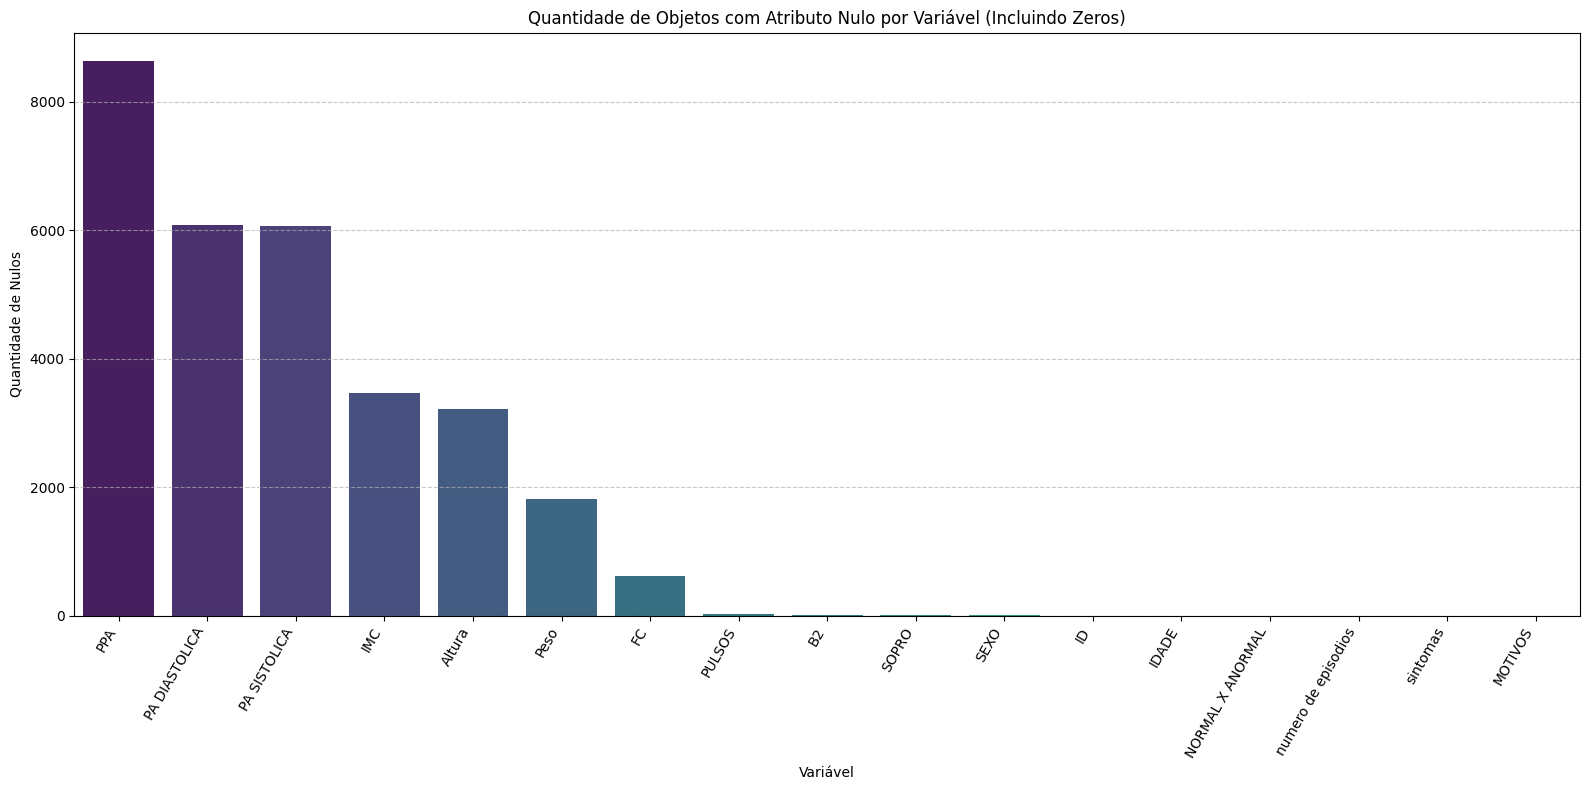

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular a contagem de nulos para CADA coluna (sem filtro)
null_counts = df.isnull().sum()

# Criar um DataFrame para facilitar a plotagem com seaborn
null_counts_df = null_counts.reset_index()
null_counts_df.columns = ['Variavel', 'Quantidade de Nulos']

# Ordenar as variáveis para melhor visualização (opcional)
null_counts_df = null_counts_df.sort_values(by='Quantidade de Nulos', ascending=False)

# Criar o gráfico de barras
plt.figure(figsize=(16, 8)) # Aumentar o tamanho para acomodar mais barras
sns.barplot(x='Variavel', y='Quantidade de Nulos', data=null_counts_df, palette='viridis', hue='Variavel', legend=False)
plt.title('Quantidade de Objetos com Atributo Nulo por Variável (Incluindo Zeros)')
plt.xlabel('Variável')
plt.ylabel('Quantidade de Nulos')
plt.xticks(rotation=60, ha='right') # Rotacionar rótulos para melhor legibilidade
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout() # Ajustar o layout para evitar cortes nos rótulos
plt.show()

In [19]:
df["PPA"].value_counts()

,count
PPA,
Normal,1784
HAS-2 PAS,73
Pre-Hipertensão PAD,73
Pre-Hipertensão PAS,48
HAS-1 PAS,47
HAS-1 PAD,26
HAS-2 PAD,21


In [20]:
print(df.isnull().sum())

ID                        0
Peso                   1819
Altura                 3215
IMC                    3468
IDADE                     0
PULSOS                   30
PA SISTOLICA           6071
PA DIASTOLICA          6080
PPA                    8639
NORMAL X ANORMAL          0
B2                       15
SOPRO                     7
FC                      611
SEXO                      4
numero de episodios       0
sintomas                  0
MOTIVOS                   0
dtype: int64


In [21]:
h = df["Altura"] / 100

# IMC a partir de peso e altura
m = df["IMC"].isna() & df["Peso"].notna() & df["Altura"].notna()
df.loc[m, "IMC"] = df.loc[m, "Peso"] / h[m]**2

# altura a partir de peso e IMC
m = df["Altura"].isna() & df["Peso"].notna() & df["IMC"].notna()
df.loc[m, "Altura"] = np.sqrt(df.loc[m, "Peso"] / df.loc[m, "IMC"]) * 100

# peso a partir de IMC e altura
m = df["Peso"].isna() & df["IMC"].notna() & df["Altura"].notna()
df.loc[m, "Peso"] = df.loc[m, "IMC"] * h[m]**2

In [22]:
print(df.isnull().sum())

ID                        0
Peso                   1718
Altura                 3215
IMC                    3468
IDADE                     0
PULSOS                   30
PA SISTOLICA           6071
PA DIASTOLICA          6080
PPA                    8639
NORMAL X ANORMAL          0
B2                       15
SOPRO                     7
FC                      611
SEXO                      4
numero de episodios       0
sintomas                  0
MOTIVOS                   0
dtype: int64


In [23]:
print(df.shape)

(10711, 17)


In [24]:
df[["Peso", "Altura", "IMC"]].isna().value_counts()

Peso   Altura  IMC  
False  False   False    7243
       True    True     1750
True   True    True     1465
       False   True      253
Name: count, dtype: int64

In [25]:
# === Recalcular PPA a partir de PA, idade, sexo e altura (Fourth Report, 2004) ===

from scipy.stats import norm

COL_PAS, COL_PAD = "PA SISTOLICA", "PA DIASTOLICA"
COL_IDADE, COL_SEXO, COL_ALTURA, COL_PPA = "IDADE", "SEXO", "Altura", "PPA"
IDADE_EM = "anos"            # "anos" ou "meses"
ALTURA_EM = "cm"             # "cm" ou "m"
MAPA_SEXO = {"M": "M", "Masculino": "M", "F": "F", "Feminino": "F"}

# ---- Tabelas LMS do CDC (lidas direto do site; carregadas uma vez por sessão) ----
URL_CDC = "https://www.cdc.gov/growthcharts/data/zscore/"
if "LMS_CDC" not in globals():
    _tabs = [pd.read_csv(URL_CDC + "lenageinf.csv"), pd.read_csv(URL_CDC + "statage.csv")]
    _tabs[0] = _tabs[0][pd.to_numeric(_tabs[0]["Agemos"], errors="coerce") < 24]
    _lms = pd.concat(_tabs, ignore_index=True)
    _lms = _lms[pd.to_numeric(_lms["Sex"], errors="coerce").notna()]
    _lms = _lms.astype({"Sex": int, "Agemos": float, "L": float, "M": float, "S": float})
    LMS_CDC = {s: _lms[_lms["Sex"] == c].sort_values("Agemos") for s, c in (("M", 1), ("F", 2))}

# ---- Coeficientes do Fourth Report, Apêndice B (confira com a tabela publicada) ----
COEF = {
    ("M", "PAS"): (102.19768, [1.82416, 0.12776, 0.00249, -0.00135], [2.73157, -0.19618, -0.04659, 0.00947], 10.7128),
    ("M", "PAD"): (61.01217, [0.68314, -0.09835, 0.01711, 0.00045], [1.46993, -0.07849, -0.03144, 0.00967], 11.6032),
    ("F", "PAS"): (102.01027, [1.94397, 0.00598, -0.00789, -0.00059], [2.03526, 0.02534, -0.01884, 0.00121], 10.4855),
    ("F", "PAD"): (60.50510, [1.01301, 0.01157, 0.00424, -0.00137], [1.16641, 0.12795, -0.03869, -0.00079], 10.9573),
}
NOMES = {0: "Normal", 1: "Pré-hipertensão", 2: "HAS estágio 1", 3: "HAS estágio 2"}


def _z_altura(altura, meses, sexo):
    z = np.full(len(altura), np.nan)
    for s, t in LMS_CDC.items():
        m = (sexo == s) & ~np.isnan(altura) & (meses >= t["Agemos"].min()) & (meses <= t["Agemos"].max())
        L, M, S = (np.interp(meses[m], t["Agemos"], t[k]) for k in ("L", "M", "S"))
        L = np.where(np.abs(L) < 1e-6, 1e-6, L)   # evita divisão por zero quando L ≈ 0
        z[m] = ((altura[m] / M) ** L - 1) / (L * S)
    return z


def _classificar(pa, anos, sexo, zalt, comp, limite_adolesc):
    cls = np.full(len(pa), np.nan)
    for s in ("M", "F"):
        a, b, g, sd = COEF[(s, comp)]
        m = (sexo == s) & ~np.isnan(pa) & ~np.isnan(zalt) & (anos >= 1) & (anos < 18)
        y, z = anos[m] - 10, zalt[m]
        mu = a + sum(bj * y ** (j + 1) for j, bj in enumerate(b)) + sum(gk * z ** (k + 1) for k, gk in enumerate(g))
        p90, p95, p99 = (mu + norm.ppf(q) * sd for q in (0.90, 0.95, 0.99))
        v = pa[m]
        c = np.zeros(m.sum())
        c[(v >= p90) | (v >= limite_adolesc)] = 1
        c[v >= p95] = 2
        c[v > p99 + 5] = 3
        cls[m] = c
    return cls


_anos = df[COL_IDADE].to_numpy(float) / (12 if IDADE_EM == "meses" else 1)
_altura = df[COL_ALTURA].to_numpy(float) * (100 if ALTURA_EM == "m" else 1)
_sexo = df[COL_SEXO].map(MAPA_SEXO).to_numpy(object)
_pas, _pad = df[COL_PAS].to_numpy(float), df[COL_PAD].to_numpy(float)

_zalt = _z_altura(_altura, _anos * 12, _sexo)
_c_pas = _classificar(_pas, _anos, _sexo, _zalt, "PAS", 120)
_c_pad = _classificar(_pad, _anos, _sexo, _zalt, "PAD", 80)
_pior = np.where(np.isnan(_c_pas) | np.isnan(_c_pad), np.nan, np.fmax(_c_pas, _c_pad))

df["z_altura"] = _zalt
df["PPA_PAS_calc"] = pd.Series(_c_pas, index=df.index).map(NOMES)
df["PPA_PAD_calc"] = pd.Series(_c_pad, index=df.index).map(NOMES)
df["PPA_calc"] = pd.Series(_pior, index=df.index).map(NOMES)

# ---- Validação: PPA original x calculada, onde as duas existem ----
print("Rótulos originais da PPA:\n", df[COL_PPA].value_counts(dropna=False), "\n")
_ambos = df[COL_PPA].notna() & df["PPA_calc"].notna()
print(f"Registros com PPA original e calculada: {_ambos.sum()}")
print(f"PPA nula que pode ser preenchida: {(df[COL_PPA].isna() & df['PPA_calc'].notna()).sum()}\n")
display(pd.crosstab(df.loc[_ambos, COL_PPA], df.loc[_ambos, "PPA_calc"], margins=True))

Rótulos originais da PPA:
 PPA
NaN                    8639
Normal                 1784
HAS-2 PAS                73
Pre-Hipertensão PAD      73
Pre-Hipertensão PAS      48
HAS-1 PAS                47
HAS-1 PAD                26
HAS-2 PAD                21
Name: count, dtype: int64 

Registros com PPA original e calculada: 2072
PPA nula que pode ser preenchida: 456



PPA_calc,HAS estágio 1,HAS estágio 2,Normal,Pré-hipertensão,All
PPA,,,,,
HAS-1 PAD,22,0,0,4,26
HAS-1 PAS,42,0,0,5,47
HAS-2 PAD,18,2,1,0,21
HAS-2 PAS,36,37,0,0,73
Normal,0,0,1712,72,1784
Pre-Hipertensão PAD,8,0,11,54,73
Pre-Hipertensão PAS,6,0,2,40,48
All,132,39,1726,175,2072
